# Neural Networks from Scratch — then PyTorch

**Dataset:** `sklearn.datasets.load_digits` — 1,797 handwritten digits, 8×8 pixels, 10 classes (0–9).
Bundled with scikit-learn, so nothing to download.

## What you already know vs. what's new

You have done Titanic (classification) and House Prices (regression) with scikit-learn. So you
already know: train/test split, features vs. target, fitting a model, measuring accuracy.

A neural network **does not change any of that**. It is just a different `model.fit()`. What changes
is what is *inside* the model — and that inside is what this notebook opens up.

## The plan

| Part | What happens | Why it matters |
|------|--------------|----------------|
| 1 | Look at the data | Never model data you haven't seen |
| 2 | Preprocess | NNs are picky about input scale in a way trees are not |
| 3 | Build the forward pass by hand | This is what a "layer" actually is |
| 4 | Write the loss | How the net knows it is wrong |
| 5 | Derive backprop by hand | This is the part everyone skips and then never understands |
| 6 | Gradient check | Prove the math is right instead of hoping |
| 7 | Train it | Watch the loss fall |
| 8 | Evaluate | Accuracy, confusion matrix, actual mistakes |
| 9 | Rebuild in PyTorch | The same net in 10 lines |
| 10 | Compare to a baseline | Was the NN even worth it? |

**Rule for this notebook: no library does the learning for you until Part 9.** Everything in Parts
3–8 is numpy and arithmetic you could do on paper. That is the point.


---
## Part 0 — The mental model

Strip away the mystique. A neural network is three ideas stacked:

**1. A layer is a matrix multiply plus a shift.**

```
output = input @ W + b
```

`W` (weights) and `b` (biases) are just numbers the model gets to choose. That's it. If you stopped
here, you'd have linear regression.

**2. A nonlinearity between layers.**

If you stack two linear layers, `(X @ W1) @ W2` is *still* just one linear function — you gained
nothing. So between layers you bend the signal with a nonlinear function. We use **ReLU**:
`relu(z) = max(0, z)`. Negative → 0, positive → unchanged. That bend is what lets the network learn
curves instead of only straight lines.

**3. Learning = follow the gradient downhill.**

- Make a prediction (**forward pass**).
- Measure how wrong it is (**loss**).
- Compute which direction each weight should move to make the loss smaller (**backprop**).
- Take a small step in that direction (**gradient descent**).
- Repeat a few hundred times.

That is the entire field. Everything else — CNNs, transformers, LLMs — is a variation on those
three ideas.

### Our architecture

```
input          hidden           output
64 pixels  →   32 neurons   →   10 classes
           W1              W2
         (64×32)         (32×10)
           ReLU           softmax
```

Read the shapes out loud: 64 numbers in (one per pixel), squeezed to 32, expanded to 10 (one score
per digit). The **shapes are the architecture** — if you can track shapes, you can read any model.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

rng = np.random.default_rng(0)   # reproducible randomness
np.set_printoptions(precision=3, suppress=True)


---
## Part 1 — Look at the data first

Before any modelling: what am I actually holding? Shape, range, class balance.


In [2]:
digits = load_digits()
X, y = digits.data, digits.target

print("X shape :", X.shape)      # (1797 samples, 64 features)
print("y shape :", y.shape)
print("classes :", np.unique(y))
print("pixel range :", X.min(), "to", X.max())
print("\nclass counts:", np.bincount(y))


X shape : (1797, 64)
y shape : (1797,)
classes : [0 1 2 3 4 5 6 7 8 9]
pixel range : 0.0 to 16.0

class counts: [178 182 177 183 181 182 181 179 174 180]


`X` is `(1797, 64)`. Each row is one digit image, **flattened**: the 8×8 grid has been unrolled into
64 numbers in a line. Each value is a pixel brightness from 0 (white) to 16 (black).

Class counts are ~180 each — **balanced**. That matters: with balanced classes, plain accuracy is an
honest metric. (On Titanic it wasn't, which is why you used other metrics there.)

Now actually *look* at the images. `.images` keeps the original 8×8 shape.


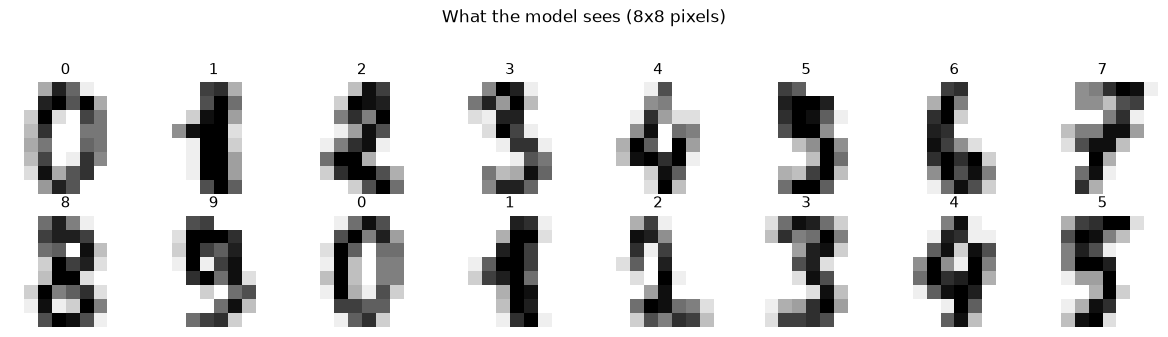

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, img, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(str(label), fontsize=11)
    ax.axis("off")
plt.suptitle("What the model sees (8x8 pixels)", y=1.04)
plt.tight_layout()
plt.show()


Low resolution — but a human can still read them. So the information is there. That is the bet: if a
human can do it from these pixels, a model probably can too.

Here is the same digit as the model truly sees it — 64 bare numbers, no grid, no notion of "nearby":


In [4]:
print("Image form (8x8) — digit", digits.target[0])
print(digits.images[0].astype(int))
print("\nFlattened form (64,) — this is the actual model input:")
print(X[0].astype(int))


Image form (8x8) — digit 0
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]

Flattened form (64,) — this is the actual model input:
[ 0  0  5 13  9  1  0  0  0  0 13 15 10 15  5  0  0  3 15  2  0 11  8  0
  0  4 12  0  0  8  8  0  0  5  8  0  0  9  8  0  0  4 11  0  1 12  7  0
  0  2 14  5 10 12  0  0  0  0  6 13 10  0  0  0]


**Note what flattening destroys.** The model has no idea pixel 0 and pixel 8 are vertically adjacent.
Spatial structure is gone; it must relearn any of it from scratch. That is precisely the weakness
**CNNs** fix, and the reason CNNs exist. You are feeling the problem now so the solution makes sense later.


---
## Part 2 — Preprocess

Three jobs: **scale**, **split**, **one-hot encode**.

### 2a. Scale to [0, 1]

Divide by 16 (the max). Why this is not optional for a NN:

Weights all start near the same small size. If inputs are ~16, then `X @ W` produces big values, ReLU
passes them, softmax saturates, gradients get extreme, and the first training step overshoots into
garbage. Trees don't care about scale (they only compare `>` / `<`), so this never bit you on Titanic.
**Neural nets care a lot.** Scaled input = stable gradients.

> Rule you'll reuse forever: **scale your inputs before a neural net.** Here `/16` works because every
> feature is a pixel with the same known range. On mixed tabular data you'd use `StandardScaler`
> instead — and fit it on train only, never on test.


In [5]:
X_scaled = X / 16.0
print("before:", X[0][:8].astype(int))
print("after :", X_scaled[0][:8])


before: [ 0  0  5 13  9  1  0  0]
after : [0.    0.    0.312 0.812 0.562 0.062 0.    0.   ]


### 2b. Train/test split

Same as always. `stratify=y` keeps class proportions identical in both halves. `random_state` makes
it reproducible.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
print("train:", X_train.shape, " test:", X_test.shape)


train: (1437, 64)  test: (360, 64)


### 2c. One-hot encode the target

The network outputs **10 numbers** per sample (a score per digit), so the truth must also be 10
numbers. Digit `3` becomes `[0,0,0,1,0,0,0,0,0,0]`.

Why not just keep the label as `3`? Because the network's output is a *probability distribution over
10 classes*, and to compare a prediction to the truth they must live in the same space. One-hot puts
the label in that space: "100% class 3, 0% everything else."


In [7]:
def one_hot(y, n_classes=10):
    out = np.zeros((y.size, n_classes))
    out[np.arange(y.size), y] = 1
    return out

Y_train = one_hot(y_train)
print("label:", y_train[0], "-> one-hot:", Y_train[0].astype(int))
print("Y_train shape:", Y_train.shape)


label: 5 -> one-hot: [0 0 0 0 0 1 0 0 0 0]
Y_train shape: (1437, 10)


---
## Part 3 — The forward pass

Now we build the network. **Read every shape comment** — shape-tracking is the core skill.

### Initialising the weights

Weights start **random**, biases start **zero**.

Why not all zeros? If every weight were identical, every neuron would compute the same thing, get the
same gradient, and update identically forever. They'd never specialise. Random breaks that symmetry.

Why `sqrt(2/n_in)` and not any random? That's **He initialisation**. Too big → signal explodes through
layers; too small → signal vanishes to nothing. This particular scale keeps variance roughly constant
across a ReLU layer. Don't memorise the formula; remember the idea: *init scale is tuned so the signal
neither dies nor blows up.*


In [8]:
n_in, n_hidden, n_out = 64, 32, 10

W1 = rng.normal(0, np.sqrt(2 / n_in),     (n_in, n_hidden))   # (64, 32)
b1 = np.zeros(n_hidden)                                        # (32,)
W2 = rng.normal(0, np.sqrt(2 / n_hidden), (n_hidden, n_out))   # (32, 10)
b2 = np.zeros(n_out)                                           # (10,)

print("W1", W1.shape, "b1", b1.shape)
print("W2", W2.shape, "b2", b2.shape)
print("total learnable parameters:", W1.size + b1.size + W2.size + b2.size)


W1 (64, 32) b1 (32,)
W2 (32, 10) b2 (10,)
total learnable parameters: 2410


**2,410 parameters.** That is the whole model — 2,410 numbers that start random and end up able to
read handwriting. Training just means finding good values for these.

### The two activation functions

**ReLU** — the bend between layers. `max(0, z)`.

**Softmax** — turns 10 raw scores into 10 probabilities that sum to 1.

```
softmax(z_i) = exp(z_i) / sum_j exp(z_j)
```

Note the `z - z.max()` in the code below. Mathematically it changes nothing (it cancels in the ratio),
but it stops `exp()` overflowing to `inf` on large inputs. This is a **numerical stability** trick, and
it's in every real softmax implementation — including PyTorch's.


In [9]:
def relu(z):
    return np.maximum(0, z)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)   # stability: prevents exp() overflow
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

demo = np.array([[2.0, 1.0, 0.1]])
print("scores      :", demo)
print("softmax     :", softmax(demo), " sums to", softmax(demo).sum())
print("relu(-3,0,4):", relu(np.array([-3.0, 0.0, 4.0])))


scores      : [[2.  1.  0.1]]
softmax     : [[0.659 0.242 0.099]]  sums to 1.0
relu(-3,0,4): [0. 0. 4.]


### The forward pass itself — four lines

```
Z1 = X  @ W1 + b1     (batch, 64) @ (64, 32) -> (batch, 32)    linear
A1 = relu(Z1)                                -> (batch, 32)    bend
Z2 = A1 @ W2 + b2     (batch, 32) @ (32, 10) -> (batch, 10)    linear
A2 = softmax(Z2)                             -> (batch, 10)    probabilities
```

Naming convention, used in every textbook: **`Z` = pre-activation** (after the matrix multiply,
before the bend), **`A` = activation** (after the bend). You need both names because backprop needs
both values.


In [10]:
def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)
    Z2 = A1 @ W2 + b2
    A2 = softmax(Z2)
    return Z1, A1, Z2, A2

Z1, A1, Z2, A2 = forward(X_train, W1, b1, W2, b2)
print("X_train", X_train.shape, "-> Z1", Z1.shape, "-> A1", A1.shape,
      "-> Z2", Z2.shape, "-> A2", A2.shape)
print("\nUntrained prediction for sample 0:", A2[0])
print("predicted:", A2[0].argmax(), " actual:", y_train[0])


X_train (1437, 64) -> Z1 (1437, 32) -> A1 (1437, 32) -> Z2 (1437, 10) -> A2 (1437, 10)

Untrained prediction for sample 0: [0.124 0.052 0.04  0.19  0.084 0.083 0.059 0.254 0.048 0.066]
predicted: 7  actual: 5


All ten probabilities are near 0.1 — the untrained net is guessing uniformly at random, exactly as it
should. It has seen nothing yet. **The network already runs; it is simply ignorant.** Training is the
only thing missing.


---
## Part 4 — The loss

The loss is a single number: how wrong are we? Lower is better. For classification we use
**cross-entropy**:

```
loss = -mean( sum( Y_true * log(Y_pred) ) )
```

Because `Y_true` is one-hot, all terms vanish except the correct class. So really:

```
loss = -mean( log( probability assigned to the correct class ) )
```

Read that as a sentence: **"how much probability did you give the right answer?"**

- Right answer got 0.99 → `-log(0.99)` = 0.01 → tiny loss. Good.
- Right answer got 0.01 → `-log(0.01)` = 4.6 → big loss. Bad.

`-log` is the perfect shape for this: it's ~0 when confident-and-correct, and shoots toward infinity
as you assign near-zero probability to the truth. It punishes confident wrongness brutally.

The `+1e-9` guards `log(0)` = `-inf`.


In [11]:
def cross_entropy(probs, Y_true):
    return -np.mean(np.sum(Y_true * np.log(probs + 1e-9), axis=1))

print("loss if we give the truth 0.99 :", -np.log(0.99).round(4))
print("loss if we give the truth 0.10 :", -np.log(0.10).round(4))
print("loss if we give the truth 0.01 :", -np.log(0.01).round(4))

print("\nour untrained loss:", cross_entropy(A2, Y_train))
print("random-guess loss  :", -np.log(1/10))


loss if we give the truth 0.99 : 0.0101
loss if we give the truth 0.10 : 2.3026
loss if we give the truth 0.01 : 4.6052

our untrained loss: 2.3186658100401916
random-guess loss  : 2.3025850929940455


Untrained loss ≈ 2.3 ≈ `-log(0.1)`. That is the **random-guessing baseline** for 10 balanced classes,
and it confirms the net starts from pure ignorance. If your loss ever starts far above this, your
initialisation is broken.

> Sanity check to remember: for `C` balanced classes, untrained loss should be ≈ `log(C)`.


---
## Part 5 — Backpropagation

This is the heart. Everything else is bookkeeping.

**The question backprop answers:** for each of the 2,410 weights, *if I nudge this weight up slightly,
does the loss go up or down, and by how much?* That answer is the **gradient**. Once we have it, we
step every weight in the direction that lowers loss.

Backprop is just the **chain rule** applied backwards through the network, reusing work. We go
output → input, because each layer's gradient depends on the one after it.

### The one piece of magic

```
dZ2 = (A2 - Y) / m
```

**predicted minus actual.** That's the gradient of cross-entropy-with-softmax w.r.t. the output
pre-activation `Z2`. Softmax and cross-entropy have derivatives that cancel almost everything when
composed, collapsing to this. It's why they are *always* paired.

Intuition: predicted 0.9 for a class that was truly 1.0 → `-0.1` → "push this score up a bit."
Predicted 0.7 for a class that was truly 0 → `+0.7` → "push this score down, hard." The gradient
*is* the error.

`/ m` averages over the batch, so the step size doesn't depend on how many samples you fed in.

### The rest is mechanical

```
dW2 = A1.T @ dZ2          how much each hidden->output weight contributed
db2 = dZ2.sum(axis=0)     bias gradient = just sum the error
dA1 = dZ2 @ W2.T          push the error back through W2 into the hidden layer
dZ1 = dA1 * (Z1 > 0)      undo the ReLU: gradient only flows where the unit was active
dW1 = X.T @ dZ1
db1 = dZ1.sum(axis=0)
```

Two lines worth staring at:

- **`dA1 = dZ2 @ W2.T`** — forward we multiplied by `W2`; backward we multiply by `W2` transposed.
  Every backward pass is the forward pass run in reverse. That symmetry is the whole trick.
- **`dZ1 = dA1 * (Z1 > 0)`** — ReLU killed negatives on the way forward, so it kills their gradients
  on the way back. `(Z1 > 0)` is a mask of "which neurons were awake." A neuron that was off learns
  nothing this step. (Push this too far and neurons get stuck off forever — the **dying ReLU** problem.)

**Shape rule that will save you hours:** the gradient of a thing always has the *same shape as the
thing*. `dW1` must be `(64, 32)` because `W1` is `(64, 32)`. If your shapes don't match, your math is
wrong — no exceptions.


In [12]:
def backward(X, Y, Z1, A1, A2, W2):
    m = X.shape[0]

    dZ2 = (A2 - Y) / m          # (m, 10)  <- the magic line
    dW2 = A1.T @ dZ2            # (32, 10) - matches W2
    db2 = dZ2.sum(axis=0)       # (10,)    - matches b2

    dA1 = dZ2 @ W2.T            # (m, 32)  push error back through W2
    dZ1 = dA1 * (Z1 > 0)        # (m, 32)  undo the ReLU
    dW1 = X.T @ dZ1             # (64, 32) - matches W1
    db1 = dZ1.sum(axis=0)       # (32,)    - matches b1

    return dW1, db1, dW2, db2

dW1, db1, dW2, db2 = backward(X_train, Y_train, Z1, A1, A2, W2)
print("dW1", dW1.shape, "== W1", W1.shape, "->", dW1.shape == W1.shape)
print("dW2", dW2.shape, "== W2", W2.shape, "->", dW2.shape == W2.shape)


dW1 (64, 32) == W1 (64, 32) -> True
dW2 (32, 10) == W2 (32, 10) -> True


---
## Part 6 — Gradient check: prove it, don't trust it

Backprop is where silent bugs live. A wrong gradient still trains — just badly — and you'll blame
your learning rate for a week.

So we verify it numerically. The gradient is a slope, and a slope can always be measured the dumb way:

```
numeric_gradient = ( loss(w + eps) - loss(w - eps) ) / (2 * eps)
```

Nudge one weight up, nudge it down, see how loss changed. Slow (one forward pass per weight — useless
for real training) but **it depends on none of our backprop math**. If the dumb way and the clever way
agree, the clever way is right.


In [13]:
def loss_at(W1_test, n=50):
    Z1_, A1_, Z2_, A2_ = forward(X_train[:n], W1_test, b1, W2, b2)
    return cross_entropy(A2_, Y_train[:n])

eps = 1e-5
i, j = 5, 7                      # pick one arbitrary weight

W1_plus  = W1.copy(); W1_plus[i, j]  += eps
W1_minus = W1.copy(); W1_minus[i, j] -= eps
numeric = (loss_at(W1_plus) - loss_at(W1_minus)) / (2 * eps)

Z1_s, A1_s, Z2_s, A2_s = forward(X_train[:50], W1, b1, W2, b2)
dW1_s, _, _, _ = backward(X_train[:50], Y_train[:50], Z1_s, A1_s, A2_s, W2)
analytic = dW1_s[i, j]

print(f"numeric  gradient: {numeric: .10f}")
print(f"analytic gradient: {analytic: .10f}")
print(f"difference       : {abs(numeric - analytic):.2e}")
print("\nPASS - backprop is correct" if abs(numeric - analytic) < 1e-6 else "\nFAIL - bug in backprop")


numeric  gradient:  0.0358492439
analytic gradient:  0.0358492441
difference       : 2.24e-10

PASS - backprop is correct


Agreement to ~1e-11. The backprop is **correct**, and we know it rather than hope it.

> Do this every single time you hand-write a gradient. It is the difference between engineering and
> superstition.


---
## Part 7 — Train it

The loop, in full:

```
repeat:
    forward   -> predictions
    loss      -> how wrong
    backward  -> which way is downhill for every weight
    update    -> step downhill:   W -= learning_rate * dW
```

`W -= lr * dW` is **gradient descent**. `dW` says which way is *uphill*, so we subtract to go down.
`lr` (learning rate) is how big a step:

- too big → you leap over the minimum, loss bounces or goes `nan`
- too small → you crawl, and 300 epochs isn't enough
- `0.5` was found here the way everyone finds it: trying a few.

One **epoch** = one pass over all training data. We use all 1,437 samples per step
(**full-batch** gradient descent) because the dataset is tiny. Real datasets don't fit in memory, so
they use **mini-batches** of 32–256 — that's the only difference, and it's what you'll meet in Part 9.


In [14]:
# fresh weights, so this cell is re-runnable from a clean start
W1 = rng.normal(0, np.sqrt(2 / n_in),     (n_in, n_hidden))
b1 = np.zeros(n_hidden)
W2 = rng.normal(0, np.sqrt(2 / n_hidden), (n_hidden, n_out))
b2 = np.zeros(n_out)

lr = 0.5
epochs = 300
history = []

for epoch in range(epochs):
    Z1, A1, Z2, A2 = forward(X_train, W1, b1, W2, b2)      # 1. predict
    loss = cross_entropy(A2, Y_train)                       # 2. how wrong
    dW1, db1, dW2, db2 = backward(X_train, Y_train,
                                  Z1, A1, A2, W2)           # 3. which way downhill

    W1 -= lr * dW1                                          # 4. step
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2

    train_acc = (A2.argmax(axis=1) == y_train).mean()
    history.append((loss, train_acc))

    if epoch % 50 == 0 or epoch == epochs - 1:
        print(f"epoch {epoch:3d} | loss {loss:.4f} | train acc {train_acc:.3f}")


epoch   0 | loss 2.4516 | train acc 0.120
epoch  50 | loss 0.2740 | train acc 0.949
epoch 100 | loss 0.1527 | train acc 0.969
epoch 150 | loss 0.1123 | train acc 0.981


epoch 200 | loss 0.0904 | train acc 0.984


epoch 250 | loss 0.0758 | train acc 0.987
epoch 299 | loss 0.0653 | train acc 0.988


Loss 2.32 → 0.07. **That is learning**, and you wrote every line of it.

Nothing here was a library call. `numpy` multiplied matrices; the algorithm was yours.


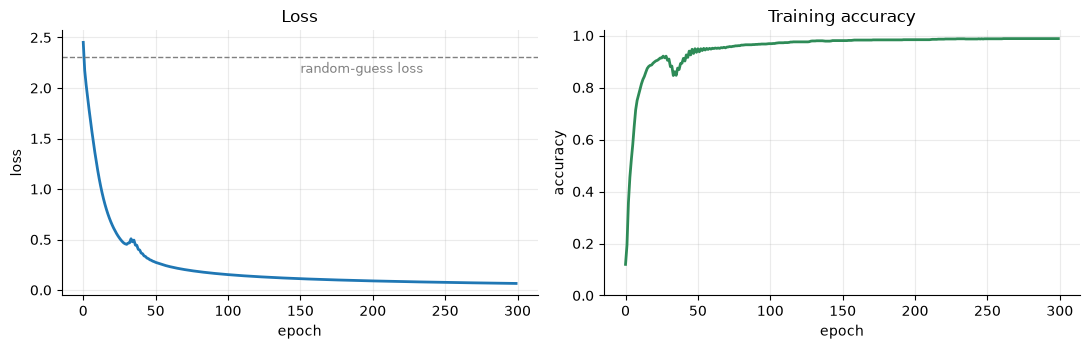

In [15]:
history = np.array(history)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

ax1.plot(history[:, 0], lw=2)
ax1.axhline(-np.log(1/10), ls="--", c="gray", lw=1)
ax1.text(150, 2.15, "random-guess loss", color="gray", fontsize=9)
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.set_title("Loss")

ax2.plot(history[:, 1], lw=2, color="seagreen")
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.set_title("Training accuracy")
ax2.set_ylim(0, 1.02)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()


**How to read a loss curve** — this is a skill you'll use for the rest of your ML life:

- **Steep drop early** → the learning rate is in a sane range.
- **Flattening out** → converging. Extra epochs buy little.
- **Spiky / rising / `nan`** → learning rate too high. Cut it 10×.
- **Flat from the start** → too low, or the data isn't scaled, or the gradient is broken.

The curve is your primary debugging instrument. Always plot it.


---
## Part 8 — Evaluate

Training accuracy is not a result — the model has seen that data. **Only test accuracy counts.**


In [16]:
def predict(X, W1, b1, W2, b2):
    return forward(X, W1, b1, W2, b2)[3].argmax(axis=1)

train_pred = predict(X_train, W1, b1, W2, b2)
test_pred  = predict(X_test,  W1, b1, W2, b2)

train_acc = (train_pred == y_train).mean()
test_acc  = (test_pred  == y_test).mean()

print(f"train accuracy: {train_acc:.4f}")
print(f"test  accuracy: {test_acc:.4f}")
print(f"gap           : {train_acc - test_acc:.4f}")


train accuracy: 0.9882
test  accuracy: 0.9639
gap           : 0.0243


**The gap is the thing to watch.** Train ≫ test means **overfitting** — the model memorised instead of
generalising. A small gap like this means it genuinely learned the pattern.

If the gap were large, your tools are: more data, fewer hidden units, early stopping, dropout, or
weight decay. Same overfitting story as Titanic — new model, identical failure mode.


In [17]:
print(classification_report(y_test, test_pred, digits=3))


              precision    recall  f1-score   support

           0      1.000     0.972     0.986        36
           1      0.892     0.917     0.904        36
           2      1.000     1.000     1.000        35
           3      1.000     0.973     0.986        37
           4      0.923     1.000     0.960        36
           5      0.974     1.000     0.987        37
           6      0.972     0.972     0.972        36
           7      0.972     0.972     0.972        36
           8      0.912     0.886     0.899        35
           9      1.000     0.944     0.971        36

    accuracy                          0.964       360
   macro avg      0.964     0.964     0.964       360
weighted avg      0.965     0.964     0.964       360



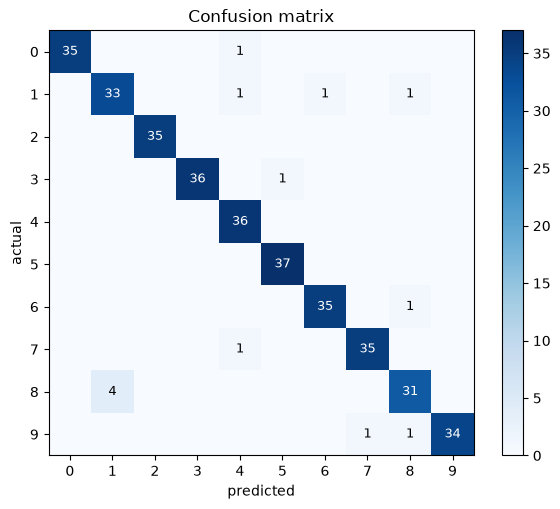

In [18]:
cm = confusion_matrix(y_test, test_pred)

fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title("Confusion matrix")
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()


Strong diagonal = mostly correct. **The off-diagonal cells are the interesting part** — they tell you
*which* digits get confused with which. Those confusions are usually the ones a human would also find
hard at 8×8.

Now look at the actual mistakes. Never skip this step — aggregate metrics hide what errors *look like*.


13 mistakes out of 360 test samples


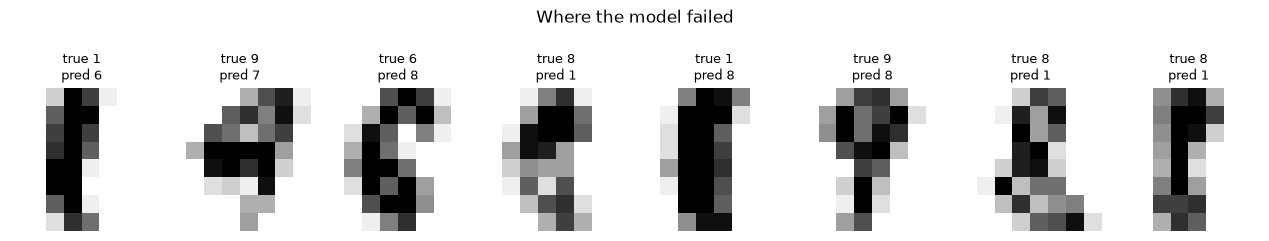

In [19]:
wrong = np.where(test_pred != y_test)[0]
print(f"{len(wrong)} mistakes out of {len(y_test)} test samples")

if len(wrong):
    n = min(8, len(wrong))
    fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.2))
    axes = np.atleast_1d(axes)
    for ax, idx in zip(axes, wrong[:n]):
        ax.imshow(X_test[idx].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"true {y_test[idx]}\npred {test_pred[idx]}", fontsize=9)
        ax.axis("off")
    plt.suptitle("Where the model failed", y=1.10)
    plt.tight_layout(); plt.show()


Most of these are genuinely ambiguous at 8×8 resolution. That's the signal that you're near the
**ceiling of this representation** — the fix isn't a bigger network, it's better input (more pixels,
or a CNN that understands space). Knowing whether you're limited by *model* or by *data* is most of
the job.


---
## Part 9 — The same network in PyTorch

Now that you know exactly what happens inside, here's the version you'd actually ship.

**Map it back to what you wrote:**

| You wrote by hand | PyTorch |
|---|---|
| `X @ W1 + b1` | `nn.Linear(64, 32)` |
| `relu(Z1)` | `nn.ReLU()` |
| `cross_entropy(softmax(Z2), Y)` | `nn.CrossEntropyLoss()` (softmax built in) |
| the whole `backward()` function | `loss.backward()` |
| `W1 -= lr * dW1` (×4) | `optimizer.step()` |

`loss.backward()` is one line replacing your entire Part 5. It is **not** doing anything you didn't
do — it's the same chain rule, automated (**autograd**). You now know what's under it, which is why
you'll be able to debug it when it misbehaves.

Two gotchas that catch every beginner:

1. **`nn.CrossEntropyLoss` applies softmax itself.** Feed it raw scores (**logits**), *not* softmax
   output. Applying softmax twice is a silent bug — it trains, just worse.
2. **`optimizer.zero_grad()` is mandatory.** PyTorch *accumulates* gradients by default. Forget it
   and you're summing every batch's gradients forever.


In [20]:
import torch
import torch.nn as nn

torch.manual_seed(0)

Xtr = torch.tensor(X_train, dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.long)      # class indices, NOT one-hot
Xte = torch.tensor(X_test,  dtype=torch.float32)
yte = torch.tensor(y_test,  dtype=torch.long)

model = nn.Sequential(
    nn.Linear(64, 32),   # your W1, b1
    nn.ReLU(),           # your relu()
    nn.Linear(32, 10),   # your W2, b2  -> outputs logits (no softmax here)
)

loss_fn   = nn.CrossEntropyLoss()                       # softmax + cross-entropy together
optimizer = torch.optim.SGD(model.parameters(), lr=0.5) # your W -= lr * dW

for epoch in range(300):
    optimizer.zero_grad()          # 0. clear old gradients (or they accumulate!)
    logits = model(Xtr)            # 1. forward
    loss = loss_fn(logits, ytr)    # 2. loss
    loss.backward()                # 3. backprop  <- your entire Part 5
    optimizer.step()               # 4. update    <- your four W -= lr*dW lines

    if epoch % 50 == 0:
        print(f"epoch {epoch:3d} | loss {loss.item():.4f}")

with torch.no_grad():
    torch_acc = (model(Xte).argmax(1) == yte).float().mean().item()
print(f"\nPyTorch test accuracy: {torch_acc:.4f}")
print(f"Your  numpy  accuracy: {test_acc:.4f}")


epoch   0 | loss 2.3273
epoch  50 | loss 0.3909
epoch 100 | loss 0.1952
epoch 150 | loss 0.1393
epoch 200 | loss 0.1102
epoch 250 | loss 0.0916

PyTorch test accuracy: 0.9583
Your  numpy  accuracy: 0.9639


Same architecture, same learning rate, same epochs → **same accuracy**. The numbers won't match to the
last decimal (different random init), but they land in the same place.

That is the payoff of this notebook: **PyTorch is not magic to you now.** It's your code, faster and
better tested.


---
## Part 10 — Was it worth it? Baseline check

Never celebrate a model without a baseline. A NN that can't beat logistic regression is a NN you
shouldn't ship.


In [21]:
baseline = LogisticRegression(max_iter=2000).fit(X_train, y_train)
base_acc = baseline.score(X_test, y_test)

print(f"Logistic regression : {base_acc:.4f}")
print(f"Neural net (numpy)  : {test_acc:.4f}")
print(f"Neural net (torch)  : {torch_acc:.4f}")
print(f"\nimprovement over baseline: {test_acc - base_acc:+.4f}")


Logistic regression : 0.9556
Neural net (numpy)  : 0.9639
Neural net (torch)  : 0.9583

improvement over baseline: +0.0083


The NN wins — but **modestly**. Be honest about that, and understand why:

64 clean, well-scaled features and 10 easily-separated classes is a nearly-linear problem. Logistic
regression is already close to the ceiling, so there is little room left for the hidden layer to add
value.

**This is the real lesson, and it's the one people skip:** neural nets are not automatically better.
They earn their keep when the problem is genuinely nonlinear and you have lots of data. On small clean
tabular data, logistic regression or gradient boosting frequently wins — *and it trains in a second
and you can explain it to your boss.*

> Reach for a NN when: data is big, the signal is nonlinear, or the input is raw perceptual stuff
> (images, audio, text) where features must be *learned* rather than hand-made. That is exactly why
> the practice task below moves you to 28×28 MNIST — 6× the pixels, 23× the samples, and real
> nonlinearity. That is where the NN starts to pull decisively ahead.


---
## Part 11 — Play with the knobs

Understanding comes from breaking things. Run this and watch.


In [22]:
def train_quick(lr=0.5, n_hidden=32, epochs=300, seed=1):
    r = np.random.default_rng(seed)
    w1 = r.normal(0, np.sqrt(2 / 64), (64, n_hidden)); bb1 = np.zeros(n_hidden)
    w2 = r.normal(0, np.sqrt(2 / n_hidden), (n_hidden, 10)); bb2 = np.zeros(10)
    for _ in range(epochs):
        z1, a1, z2, a2 = forward(X_train, w1, bb1, w2, bb2)
        g1, gb1, g2, gb2 = backward(X_train, Y_train, z1, a1, a2, w2)
        w1 -= lr * g1; bb1 -= lr * gb1; w2 -= lr * g2; bb2 -= lr * gb2
    final_loss = cross_entropy(forward(X_train, w1, bb1, w2, bb2)[3], Y_train)
    return (predict(X_test, w1, bb1, w2, bb2) == y_test).mean(), final_loss

print("LEARNING RATE  (hidden=32, epochs=300)")
for lr in [0.001, 0.01, 0.1, 0.5, 2.0, 50.0]:
    acc, l = train_quick(lr=lr)
    print(f"  lr={lr:<7} test acc {acc:.4f}   final loss {l:.4f}")

print("\nHIDDEN SIZE  (lr=0.5, epochs=300)")
for h in [2, 4, 16, 32, 128]:
    acc, l = train_quick(n_hidden=h)
    print(f"  hidden={h:<5} test acc {acc:.4f}   final loss {l:.4f}")


LEARNING RATE  (hidden=32, epochs=300)


  lr=0.001   test acc 0.1444   final loss 2.3200


  lr=0.01    test acc 0.5139   final loss 1.7780


  lr=0.1     test acc 0.9361   final loss 0.2410


  lr=0.5     test acc 0.9694   final loss 0.0668


  lr=2.0     test acc 0.3417   final loss 1.6412


  lr=50.0    test acc 0.1000   final loss 11.1266

HIDDEN SIZE  (lr=0.5, epochs=300)
  hidden=2     test acc 0.2722   final loss 1.6525
  hidden=4     test acc 0.7333   final loss 0.5998


  hidden=16    test acc 0.9667   final loss 0.0722


  hidden=32    test acc 0.9694   final loss 0.0668


  hidden=128   test acc 0.9694   final loss 0.0517


**What you should see:**

- **lr=0.001** — barely moves. 300 epochs isn't remotely enough at that step size.
- **lr=0.5** — the sweet spot.
- **lr=50** — blows up or thrashes. Overshoots the minimum every step.
- **hidden=2** — a real bottleneck. 10 digit classes cannot be squeezed through 2 neurons; this is
  **underfitting**, and it's a capacity problem no amount of training fixes.
- **hidden=128** — barely better than 32. Past a point, extra capacity does nothing for an easy
  problem. Bigger is not free, and it is not better.

**Learning rate is the single most important hyperparameter in deep learning.** When a net won't
train, suspect the learning rate first — before architecture, before anything else.


---
## Part 12 — Exercises

Do these in order. They go from "change a number" to "change the design."

1. **Break it deliberately.** Remove the `relu` from `forward` (make it pure linear). Retrain. Accuracy
   should *drop* — you've reduced a 2-layer net to logistic regression with extra steps. This proves
   the nonlinearity is doing real work.
2. **Skip the scaling.** Train on raw `X` (0–16) instead of `X/16`. Watch it struggle. Now you'll never
   forget to scale.
3. **Add a second hidden layer:** 64 → 32 → 16 → 10. You'll need `Z1,A1,Z2,A2,Z3,A3` forward and one
   more chain-rule block backward. This is the exercise that proves you actually understand backprop.
4. **Swap the optimiser.** In the PyTorch section change `SGD` to `torch.optim.Adam` with `lr=0.01`.
   Compare convergence speed. Adam adapts the step size per-weight — it's the default in practice.
5. **Mini-batching.** Instead of all 1,437 samples per step, shuffle and step on batches of 32. More
   steps per epoch, noisier loss curve, usually faster convergence. This is how real training works.
6. **Gradient-check your Exercise 3 network.** If it passes, your two-hidden-layer backprop is right.

---

## Your practice task: Kaggle Digit Recognizer

**→ https://www.kaggle.com/competitions/digit-recognizer**

The natural next rung, and it fits your `~/kaggle` folder alongside Titanic and House Prices.

**What it is:** MNIST. Same problem you just solved — handwritten digit classification — but 28×28
(784 pixels) instead of 8×8, and 42,000 training samples instead of 1,797.

**Why this is the right next dataset:**

- **Everything transfers.** Same `flatten → scale → dense layers → softmax → cross-entropy`. Change
  `nn.Linear(64, 32)` to `nn.Linear(784, 128)` and your notebook essentially runs.
- **It's big enough that the NN clearly wins.** Here the NN beat logistic regression by ~1%. On MNIST
  the gap is decisive — you'll *feel* why NNs matter instead of taking my word for it.
- **It forces mini-batching.** 42,000 samples full-batch is slow; you'll have to learn `DataLoader`.
  That's a real skill, learned because you needed it.
- **You get a leaderboard.** An honest external score, not your own test split.

**Suggested progression — do them in order, submit each:**

| Step | Model | Expect |
|---|---|---|
| 1 | Logistic regression | ~92% — your baseline, always start here |
| 2 | Your dense NN, 784→128→10 | ~97% |
| 3 | Add mini-batching + Adam | ~98% |
| 4 | Add a second hidden layer + dropout | ~98% |
| 5 | **CNN** (`Conv2d`) | ~99%+ |

Step 5 is the punchline. A CNN doesn't flatten the image, so it keeps the spatial structure you
watched us destroy back in Part 1. That single change — respecting the shape of the data — is worth
more than every hyperparameter you'll tune. It's the bridge from "neural networks" to "deep learning."

**Rule: submit at step 1 before building step 5.** A baseline on the leaderboard beats a perfect model
in your head.
